# Ejercicios de Seaborn

# 1. Importa pandas, pyplot y seaborn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Lee 'Pokemon.csv', lee la primera columna del csv como índice del DataFrame

In [3]:
pokemon = pd.read_csv("./data/Pokemon.csv", index_col=0)
pokemon

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False
...,...,...,...,...,...,...,...,...,...,...,...,...
147,Dratini,Dragon,NaN,300,41,64,45,50,50,50,1,False
148,Dragonair,Dragon,NaN,420,61,84,65,70,70,70,2,False
149,Dragonite,Dragon,Flying,600,91,134,95,100,100,80,3,False


# 4. Mira las primeras filas del dataset para hacerte una idea de los datos cargados

In [4]:
pokemon.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


# 5. Haz un scatter plot con lmplot(), que es el método que pinta una regresión lineal
### Pasa el DataFrame como argumento del método en el parámetro llamado data

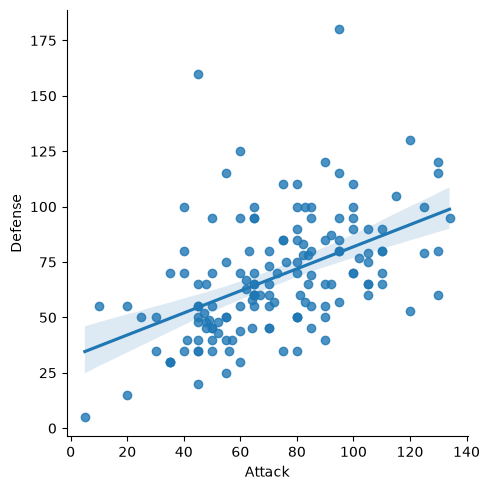

In [5]:
sns.lmplot(x="Attack", y="Defense", data=pokemon)
plt.show()

# 6. No queremos ver la línea recta de la regresión lineal.
### prueba a añadir fit_reg a falso

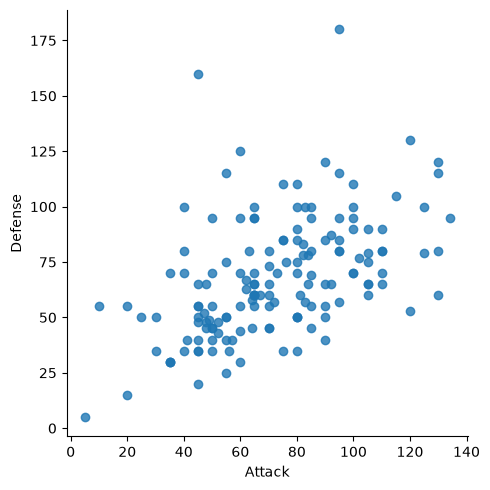

In [6]:
sns.lmplot(
    x="Attack",
    y="Defense",
    data=pokemon,
    fit_reg=False
)
plt.show()

# 7. Vamos a decir qué variable (columna del DataFrame) codifica los colores (hue)
### Que el hue sea el Stage

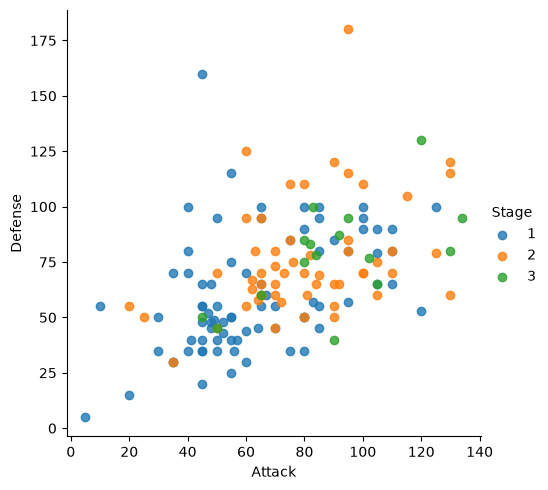

In [7]:
sns.lmplot(
    x="Attack",
    y="Defense",
    data=pokemon,
    fit_reg=False,
    hue="Stage"
)
plt.show()

# 8. Limita el eje x entre 20 y 100

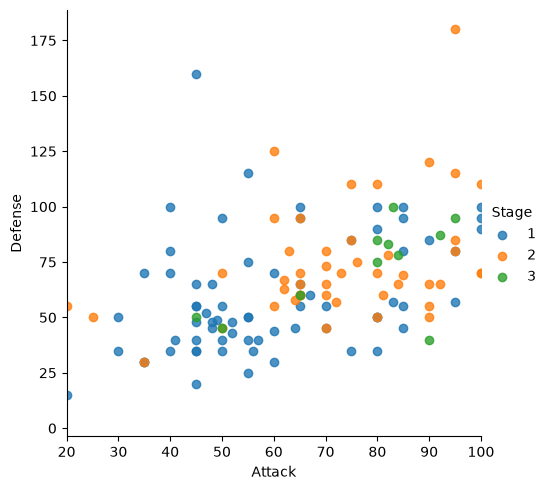

In [8]:
grafico = sns.lmplot(
    x="Attack",
    y="Defense",
    data=pokemon,
    fit_reg=False,
    hue="Stage"
)

grafico.set(xlim=(20, 100))
plt.show()

# 9. Dibuja un diagrama de cajas con el dataframe

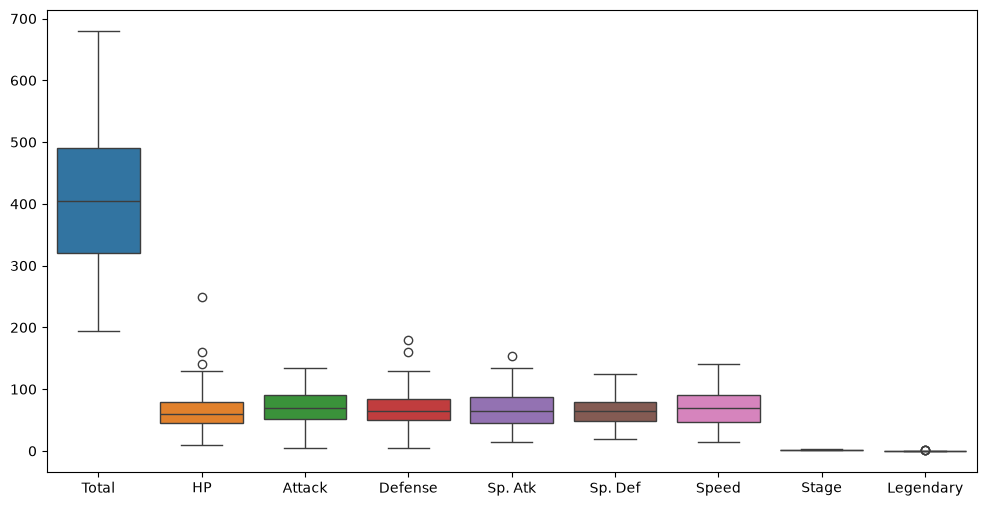

In [9]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=pokemon)

plt.show()

# 10. No nos interesan las columnas Total, Stage ni Legendary
### Bórralos del DataFrame y vuelve a dibujar el diagrama de cajas

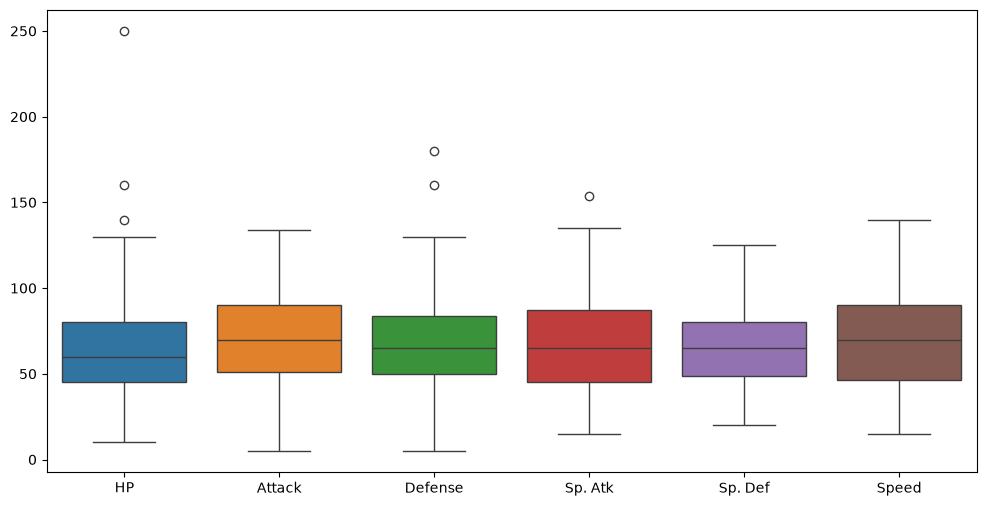

In [10]:
pokemon_stats = pokemon.drop(columns=["Total", "Stage", "Legendary"])

plt.figure(figsize=(12, 6))
sns.boxplot(data=pokemon_stats)
plt.show()

# 11. Mira cuántos 'Type 1' diferentes hay en el DataFrame

In [11]:
pokemon["Type 1"].nunique()

15

In [12]:
pokemon["Type 1"].unique()

<StringArray>
[   'Grass',     'Fire',    'Water',      'Bug',   'Normal',   'Poison',
 'Electric',   'Ground',    'Fairy', 'Fighting',  'Psychic',     'Rock',
    'Ghost',      'Ice',   'Dragon']
Length: 15, dtype: str

# 12. Quédate del Dataframe solo con los 'Type 1' iguales a 'Grass', 'Fire' o 'Water'

In [13]:
tipos = ["Grass", "Fire", "Water"]

pokemon_tipos = pokemon.loc[pokemon["Type 1"].isin(tipos)]

pokemon_tipos.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


# 13. Usa un estilo 'whitegrid'

In [14]:
df_gfw = pokemon.loc[pokemon["Type 1"].isin(["Grass", "Fire", "Water"])].copy()

In [15]:
sns.set_style("whitegrid")

# 14. Pinta diagramas de violín con el DataFrame filtrado por los 3 tipos

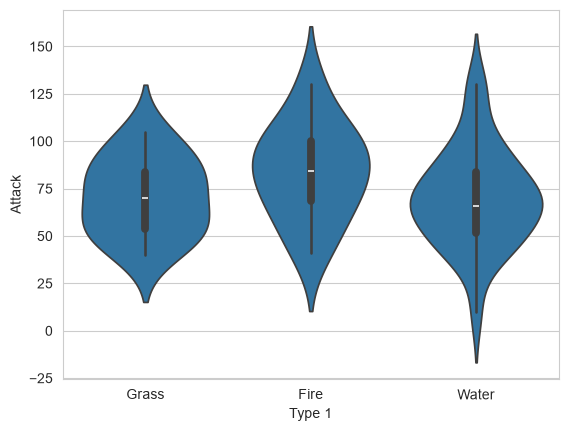

In [16]:
sns.violinplot(
    x="Type 1",
    y="Attack",
    data=df_gfw
)

plt.show()

# 15. Escribe una lista de colores con valores '#78C850', '#F08030',  '#6890F0'

In [17]:
colores_pokemon = ["#78C850", "#F08030", "#6890F0"]

# 16. Pinta de nuevo los diagramas de violín añadiendo esos colores en la paleta (palette)

/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_45608/2563751054.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


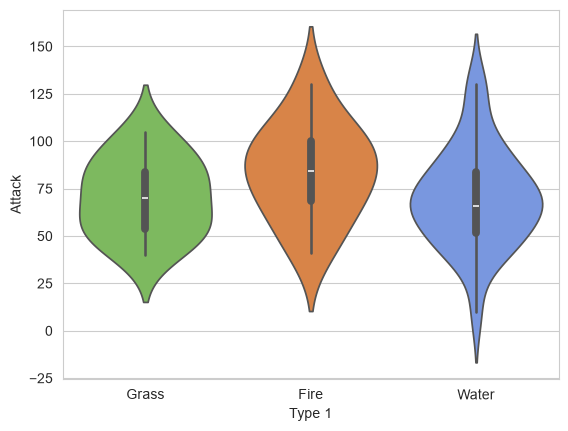

In [18]:
sns.violinplot(
    x="Type 1",
    y="Attack",
    data=df_gfw,
    palette=colores_pokemon
)

plt.show()

# 17. Con el diagrama de violín vemos la forma de la distribución, pero no sabemos si Grass tiene muchos puntos y Fire tiene muy pocos.
### Para ver esto, usamos el swarmplot.
### Pinta el último diagrama de violines pero con un swarmplot en lugar de un violin

/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_45608/1732065175.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


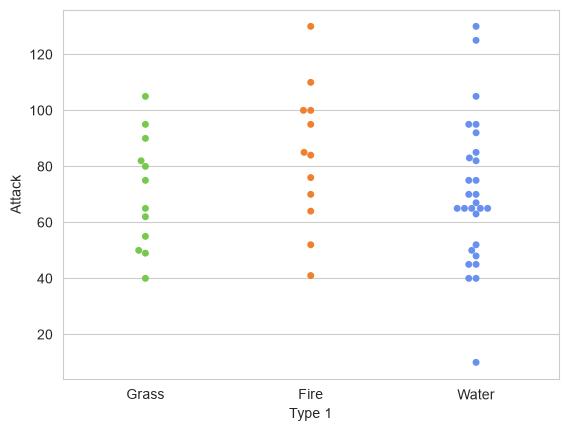

In [19]:
sns.swarmplot(
    x="Type 1",
    y="Attack",
    data=df_gfw,
    palette=colores_pokemon
)

plt.show()

# 18. Queremos ver los violines a la vez que los swarm, los podemos pintar juntos. 
### Elimina los diagramas de caja dentro de los violines con el parámetro inner = None y pon una transparencia de 0.9 en el swarmplot
### Pon un título con pyplot (como siempre)

/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_45608/2516818789.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


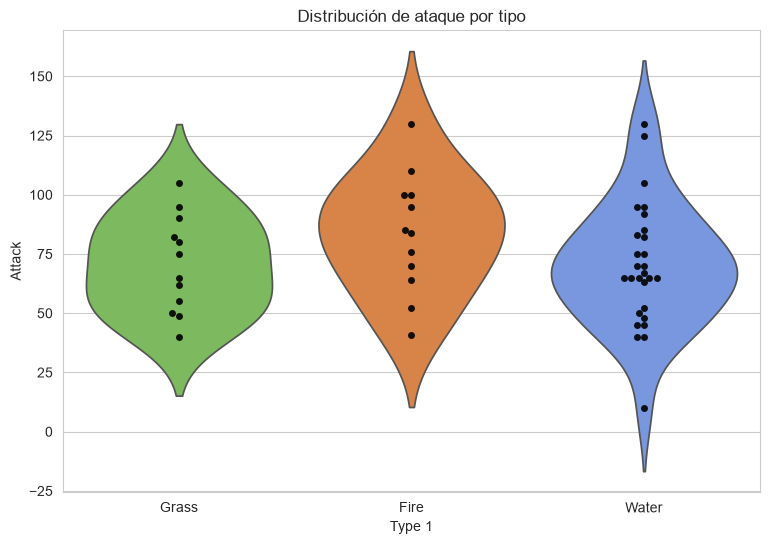

In [20]:
plt.figure(figsize=(9, 6))

sns.violinplot(
    x="Type 1",
    y="Attack",
    data=df_gfw,
    palette=colores_pokemon,
    inner=None
)

sns.swarmplot(
    x="Type 1",
    y="Attack",
    data=df_gfw,
    color="black",
    alpha=0.9
)

plt.title("Distribución de ataque por tipo")
plt.show()

# 19. Veamos la función melt() de pandas. Melt toma los valores de varias columnas y los junta todos en una misma columna nueva.
### Dado un DataFrame, melt recibe varios parámetros:
### * qué columnas del DataFrame se quedan igual
### * qué nombres de columnas del dataframe pasan a ser una columna nueva
### * cómo queremos llamar esas nuevas columnas

### Primero recuerda el Dataframe df_grass_fire_water con las primeras 5 filas

In [21]:
df_gfw.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


# 20. Queremos dejar igual las variables 'Name' y 'Type 1'
### Queremos añadir una columa nueva cuyos valores sean las columnas que queremos apilar y que se llame 'New Column'
### Escribimos df_gfw.melt(id_vars=['Name', 'Type 1'], value_vars=[...], var_name='New Column')

In [22]:
df_melted = df_gfw.melt(
    id_vars=["Name", "Type 1"],
    value_vars=["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"],
    var_name="New Column",
    value_name="Value"
)

df_melted.head()

,Name,Type 1,New Column,Value
0,Bulbasaur,Grass,HP,45
1,Ivysaur,Grass,HP,60
2,Venusaur,Grass,HP,80
3,Charmander,Fire,HP,39
4,Charmeleon,Fire,HP,58


# 21. Pintamos el swarmplot con el melted y entendemos la información

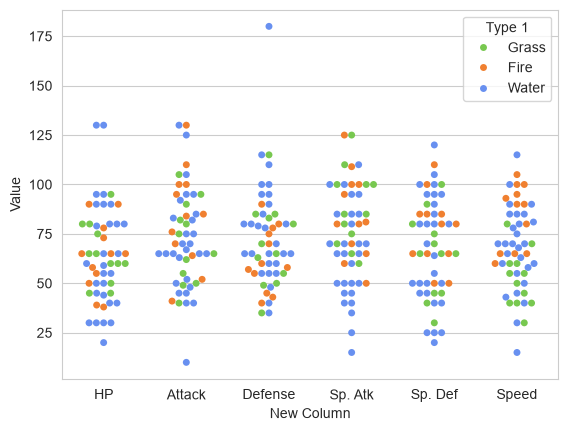

In [23]:
sns.swarmplot(
    x="New Column",
    y="Value",
    data=df_melted,
    hue="Type 1",
    palette=colores_pokemon
)

plt.show()

# 22. Basándote en el gráfico anterior, define el tamaño de la figura en (10,6) (usa plt)
### En el swarmplot añade el argumento dodge a True y usa la anterior paleta de colores Pokemon

### Dodge en inglés es "esquivar", ¿qué diferencia ves?

## Usando plt 
### fija el límite del eje Y entre 0 y 200
### fija la leyenda con bbox_to_anchor en upper left. Pista: upper left es el código 2 y se usa el parámetro loc.

### Observa que incluso usando Seaborn, usamos Pyplot para trabajar con los ejes, la leyenda y el tamaño
### Lo importante es que Seaborn y Pyplot conviven bien juntos

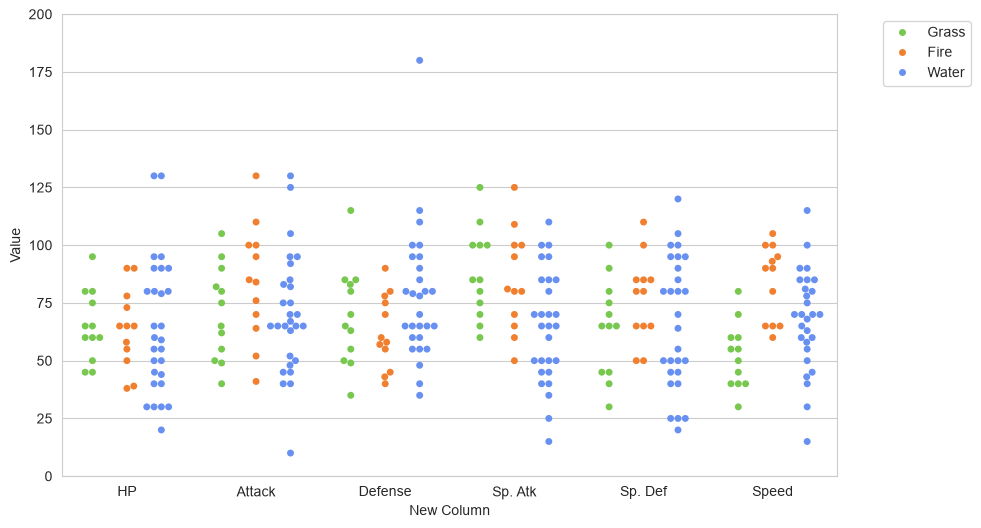

In [ ]:
plt.figure(figsize=(10, 6))

sns.swarmplot(
    x="New Column",
    y="Value",
    data=df_melted,
    hue="Type 1",
    palette=colores_pokemon,
    dodge=True #dodge=True para que los puntos no se superpongan.
)

plt.ylim(0, 200)
plt.legend(loc=2, bbox_to_anchor=(1.05, 1))
plt.show()

# 23. Mapas de calor
### Calcula las correlaciones del primer DataFrame original df
### Pista: las correlaciones se calculan con el método corr()
### Recuerda: las correlaciones miden entre dos variables, si varío una, cuánto me varía la otra (cómo están de relacionadas)

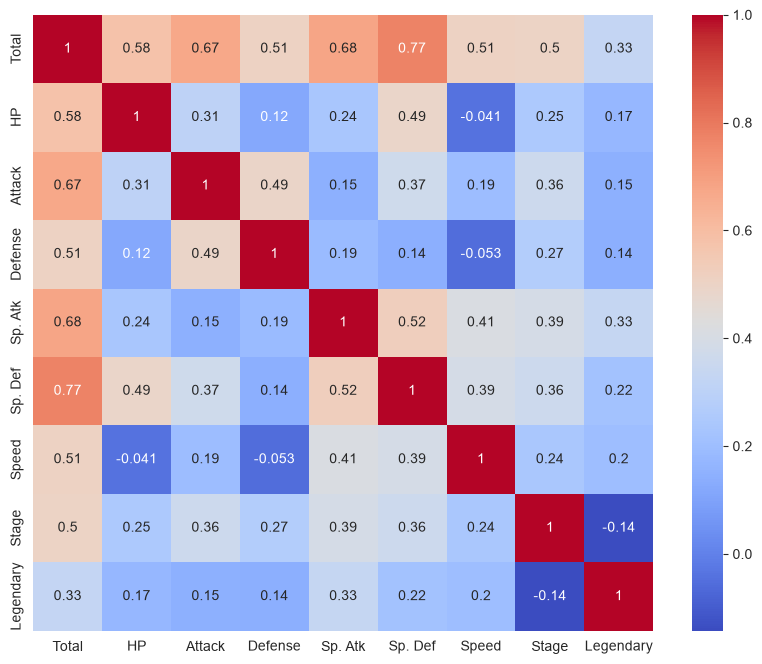

In [27]:
correlaciones = pokemon.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, cmap="coolwarm")
plt.show()

### ¿la correlación entre qué valores se encuentra?
### la autocorrelación es la correlación de una variable consigo misma, ¿qué aprecias?
### Encuentra dos variables que veas que están fuertemente relacionadas según la correlación

Las correlaciones van de -1 a 1:
- 1: relación positiva perfecta.
- -1: relación negativa perfecta.
- 0: sin relación lineal.

La diagonal vale siempre 1, porque una variable está perfectamente correlacionada consigo misma. Total suele estar muy relacionado con las estadísticas individuales.

# 24. Pinta el histograma y la densidad de probabilidad del nivel de defensa usando el DataFrame original

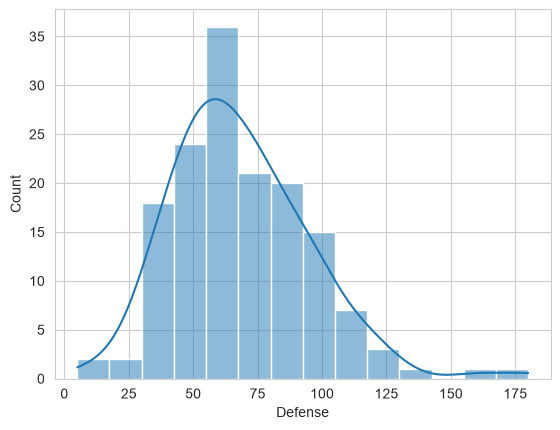

In [28]:
sns.histplot(
    data=pokemon,
    x="Defense",
    kde=True
)

plt.show()

# 25. Pinta un diagrama de barras de la columna 'Type 1' usando el DataFrame original
### Usa un sns.countplot
### Usa plt.xticks y gira las etiquetas

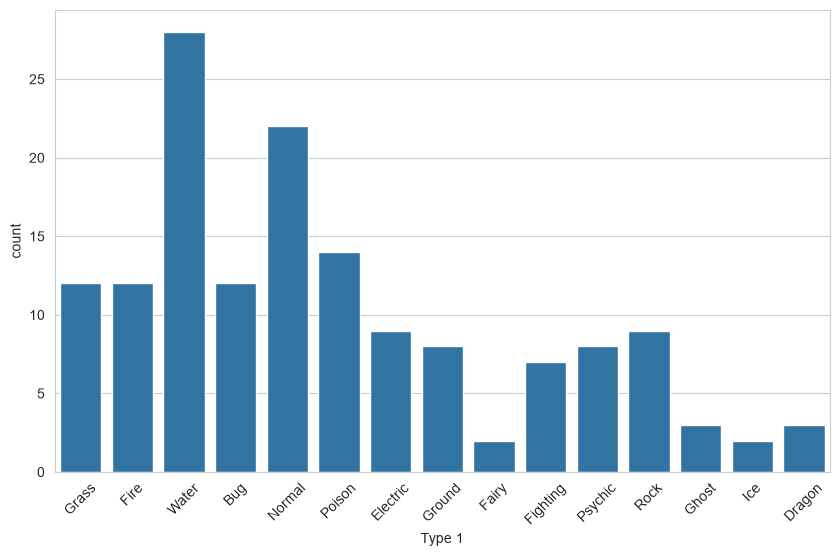

In [29]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=pokemon,
    x="Type 1"
)

plt.xticks(rotation=45)
plt.show()

# 26. Usa catplot con el DataFrame original.
### Muestra el valor de Defense según el 'Type 1', muestra un subplot para legendarios y otro para no legendarios y divide los colores según el Type 2

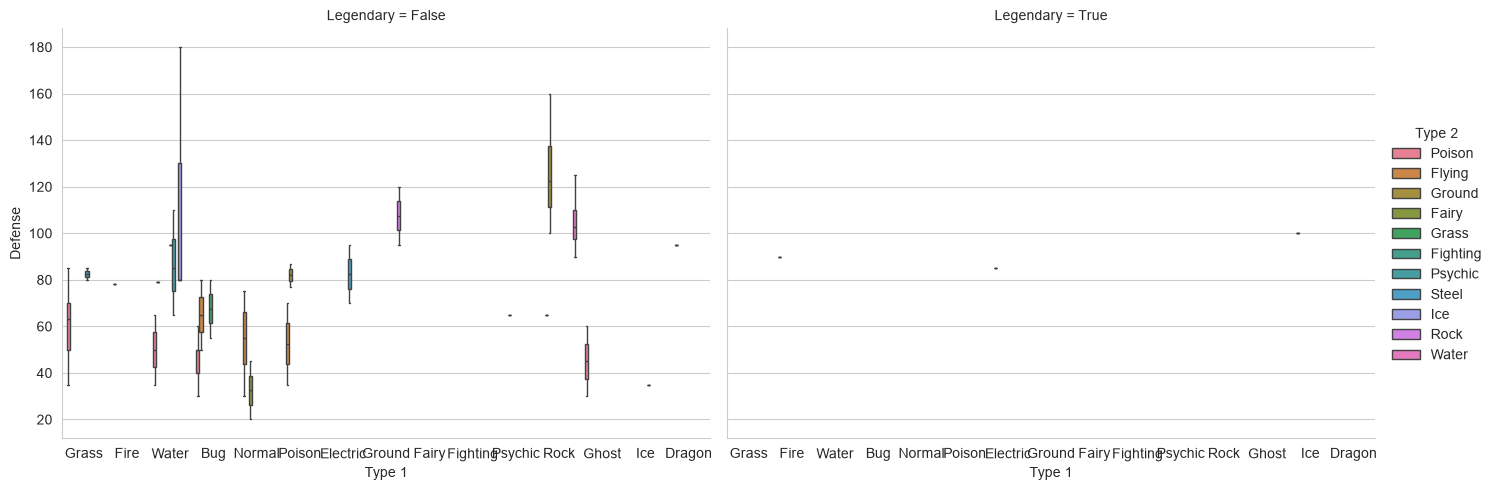

In [ ]:
sns.catplot(
    data=pokemon,
    x="Type 1",
    y="Defense",
    hue="Type 2",
    col="Legendary",# Crea un subplot
    kind="box",
    height=5,
    aspect=1.4
)

plt.show()

# 27. Muestra una función distribución de probabilidad con kdeplot (curvas de nivel) de la defensa respecto al ataque.
### Di un bin 2D donde caigan muchos puntos (ataque, defensa).

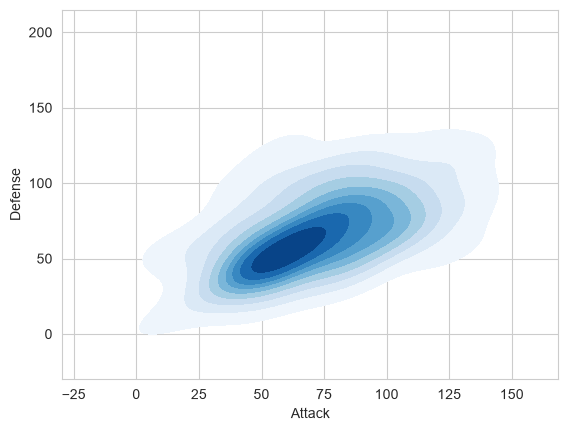

In [39]:
sns.kdeplot(
    data=pokemon,
    x="Attack",
    y="Defense",
    fill=True,
    cmap="Blues",
    thresh=0.05
)

plt.show()

# 28. Pinta una distribución de probabilidad conjunta con jointplot, pintando la defensa respecto al ataque del DataFrame original

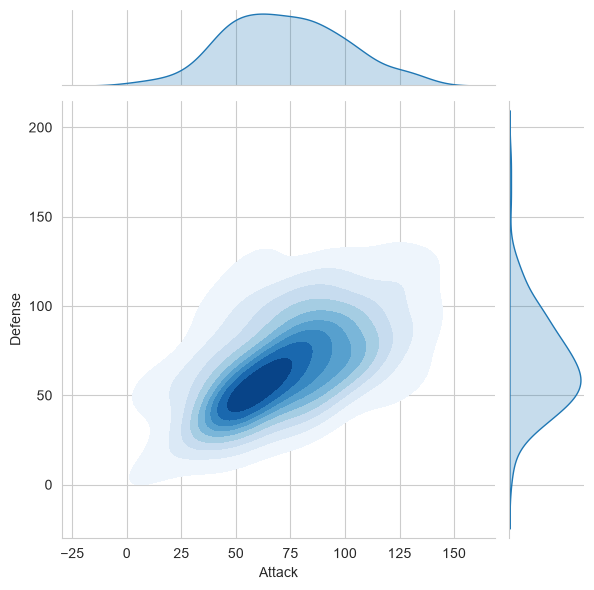

In [42]:
sns.jointplot(
    data=pokemon,
    x="Attack",
    y="Defense",
    kind="kde",
    fill=True,
    cmap="Blues"
)

plt.show()